# Movie Recommendation System: Find Films with Similar Plots

TEAM 2: Nurgaliyev Batyrkhan, Lipyavko Anastasia, Belmach Mariia

**How our movie recommendation system works?**

The user gives a movie (or describes one in their own words), and the system recommends movies with the most similar plot.

An AI model turns every plot description into a list of numbers (a *vector*). Similar plots get similar vectors,
so "find similar movies" becomes "find the closest vectors".

Chosen Dataset - [AiresPucrs/tmdb-5000-movies](https://huggingface.co/datasets/AiresPucrs/tmdb-5000-movies) (~4 800 movies)

Model - [sentence-transformers/all-mpnet-base-v2](https://huggingface.co/sentence-transformers/all-mpnet-base-v2)

## 1. Setup
We install two libraries that Colab does not always have, then import everything we need.

In [1]:
!pip install -q sentence-transformers datasets

In [2]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
import os
os.makedirs("results/figures", exist_ok=True)

## 2. Dataset

We took TMDB 5000 Movie Dataset loaded from Hugging Face.

The size is about 4 800 movies.

Key metadata is: movie titles, *plot overviews (the texts our model reads)*, genres (which was used only to check the results), release dates, ratings, and vote counts.


**Why we chose this dataset?**

Movies come with a plot overviews that we need to compare storylines and find similar ones. Plus genres, cast, ratings are super helpful for double-checking whether the recommendations actually make sense.

Lets look through the data:

In [3]:
df = load_dataset("AiresPucrs/tmdb-5000-movies", split="train").to_pandas()
print(df.shape)
df[["title", "genres", "overview", "vote_average"]].head()

(4803, 22)


,title,genres,overview,vote_average
0,Four Rooms,"[{""id"": 80, ""name"": ""Crime""}, {""id"": 35, ""name...",It's Ted the Bellhop's first night on the job....,6.5
1,Star Wars,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 28, ""...",Princess Leia is captured and held hostage by ...,8.1
2,Finding Nemo,"[{""id"": 16, ""name"": ""Animation""}, {""id"": 10751...","Nemo, an adventurous young clownfish, is unexp...",7.6
3,Forrest Gump,"[{""id"": 35, ""name"": ""Comedy""}, {""id"": 18, ""nam...",A man with a low IQ has accomplished great thi...,8.2
4,American Beauty,"[{""id"": 18, ""name"": ""Drama""}]","Lester Burnham, a depressed suburban father in...",7.9


## 3. Cleaning
We kept only the columns we need ("id", "title", "overview", "genres", "keywords", "cast", "crew", "release_date", "vote_average", "vote_count").
Then removed movies with no plot description (or with description that is shorter than 5 words).

Turned genres, keywords, actors and director from JSON text into normal Python lists and added two helper columns which are release year and the number of words in the overview.

After cleaning 4798 films were left.

In [4]:
df = df[["id", "title", "overview", "genres", "keywords", "cast", "crew", "release_date", "vote_average", "vote_count"]].copy()
df = df.drop_duplicates("id")
df["overview"] = df["overview"].fillna("").str.strip()
df["n_words"] = df["overview"].str.split().str.len()
df = df[df["n_words"] >= 5]

def parse_list(value):
    if isinstance(value, str):
        return json.loads(value)
    return [] if value is None or isinstance(value, float) else list(value)

df["genres"] = df["genres"].apply(lambda v: [g["name"] for g in parse_list(v)])
df["keywords"] = df["keywords"].apply(lambda v: [k["name"] for k in parse_list(v)])
df["cast_top"] = df["cast"].apply(lambda v: [a["name"] for a in parse_list(v)][:5])
df["director"] = df["crew"].apply(lambda v: [p["name"] for p in parse_list(v) if p.get("job") == "Director"])
df["year"] = pd.to_datetime(df["release_date"], errors="coerce").dt.year
df = df.sort_values("vote_count", ascending=False).reset_index(drop=True)
print(len(df), "movies after cleaning")

4798 movies after cleaning


## 4. Exploratory Data Analysis (EDA)

We use four charts that describe the data.

**Chart 1. Movies per Genre.**

 We'd like to pay special attention to this data as it shows the fundamental info for our future work. Drama (> 2,200 movies) and Comedy (~1,700 movies) dominate in the dataset (Thriller, Action too). Because these top genres appear so frequently, a simple baseline or genre-matching model can easily get high overlap scores just by recommending popular Drama or Comedy titles, which shows why comparing actual plot semantics is much more meaningful.

**Chart 2. Length of plot descriptions.**

Plot descriptions are generally from 25 to 75 words (what suits our model becase of the limits in tokens)  

**Chart 3. Release year.**

Majority of movies released between 2000 and 2016

**Chart 4. Rating**

Distribution centered around 5.8 to 6.8. This gives us a reliable quality baseline to verify whether recommended films are well-received rather than random low-rated outliers.


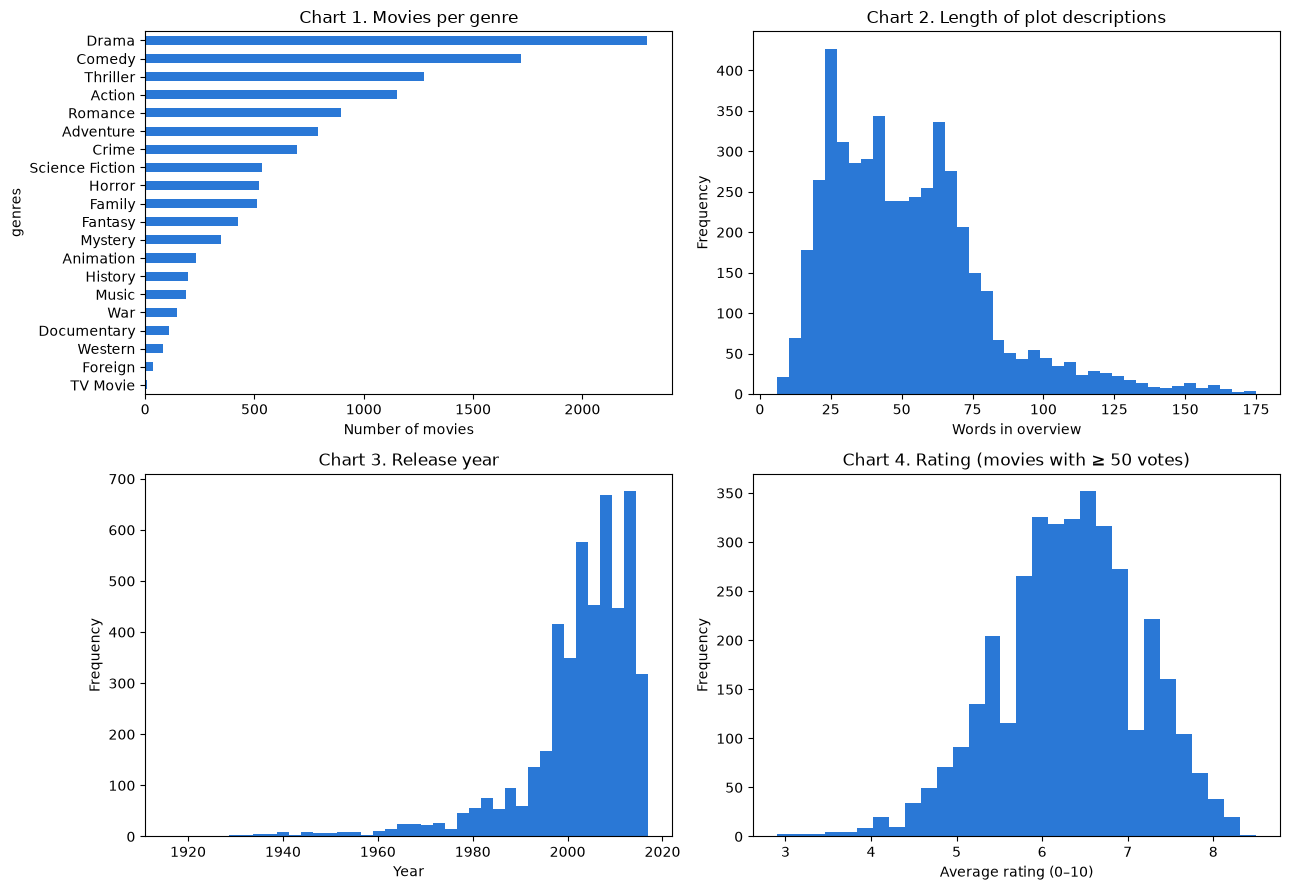

<Figure size 640x480 with 0 Axes>

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

df["genres"].explode().value_counts().plot.barh(ax=axes[0, 0], color="#2a78d6")
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("Chart 1. Movies per genre")
axes[0, 0].set_xlabel("Number of movies")

df["n_words"].plot.hist(bins=40, ax=axes[0, 1], color="#2a78d6")
axes[0, 1].set_title("Chart 2. Length of plot descriptions")
axes[0, 1].set_xlabel("Words in overview")

df["year"].plot.hist(bins=40, ax=axes[1, 0], color="#2a78d6")
axes[1, 0].set_title("Chart 3. Release year")
axes[1, 0].set_xlabel("Year")

df.loc[df["vote_count"] >= 50, "vote_average"].plot.hist(bins=30, ax=axes[1, 1], color="#2a78d6")
axes[1, 1].set_title("Chart 4. Rating (movies with ≥ 50 votes)")
axes[1, 1].set_xlabel("Average rating (0–10)")

plt.tight_layout()
plt.show()
plt.savefig("results/figures/eda_charts.png", dpi=150, bbox_inches="tight")

In [6]:
print("Top 3 genres (share of movies):")
print(df["genres"].explode().value_counts(normalize=True).head(3).round(2))
print("Average genres per movie:", round(df["genres"].apply(len).mean(), 1))
print("Median words per overview:", df["n_words"].median())
print("Movies released in 2000 or later:", round((df["year"] >= 2000).mean() * 100), "%")

Top 3 genres (share of movies):
genres
Drama       0.19
Comedy      0.14
Thriller    0.10
Name: proportion, dtype: float64
Average genres per movie: 2.5
Median words per overview: 48.0
Movies released in 2000 or later: 73 %


## 5. The model and the recommender

**Model we chose & Why**

[`sentence-transformers/all-mpnet-base-v2`](https://huggingface.co/sentence-transformers/all-mpnet-base-v2)

It reads a text and outputs **768 numbers** (an *embedding*) that represent its meaning. Texts with similar meaning get similar numbers, even if they use different words.

It was trained on > 1 billion pairs of related sentences, so it learned which texts mean similar things.


**Why this model:** it is made exactly for comparing texts, it is one of the most accurate general models of this type, and it is small enough
  (about 110 M parameters) to run on free Colab in under a minute. We do **not** train it; we use it as it is (pre-trained).

**How recommendations work:**
1. Turn every movie's plot into a vector (done once for all movies).
2. To compare two movies, compute the **cosine similarity** of their vectors: 1 = same meaning, 0 = unrelated.
3. For the chosen movie, sort all other movies by similarity and show the top ones.

In [7]:
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")

start = time.time()
embeddings = model.encode(df["overview"].tolist(), batch_size=32, show_progress_bar=True, normalize_embeddings=True)
print(f"Encoded {len(df)} movies in {time.time() - start:.1f} seconds")
print("Embeddings shape:", embeddings.shape)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Batches:   0%|          | 0/150 [00:00<?, ?it/s]

Encoded 4798 movies in 22.9 seconds
Embeddings shape: (4798, 768)


In [8]:
def find_movie(title):
    matches = df[df["title"].str.lower() == title.lower()]
    if matches.empty:
        matches = df[df["title"].str.lower().str.contains(title.lower(), regex=False)]
    if matches.empty:
        print(f"Movie '{title}' not found. Try another title.")
        return None
    return matches.index[0]

def recommend(title, k=5):
    i = find_movie(title)

    if i is None:
        return None
    scores = embeddings @ embeddings[i]
    scores[i] = -1

    top = np.argsort(-scores)[:k]

    print(f"Because you liked: {df.loc[i, 'title']} ({', '.join(df.loc[i, 'genres'])})")
    result = df.loc[top, ["title", "genres", "vote_average"]].copy()
    result["similarity"] = scores[top].round(3)
    return result.reset_index(drop=True)

def search(description, k=5):
    query = model.encode([description], normalize_embeddings=True)[0]
    scores = embeddings @ query

    top = np.argsort(-scores)[:k]

    result = df.loc[top, ["title", "genres", "vote_average"]].copy()
    result["similarity"] = scores[top].round(3)
    return result.reset_index(drop=True)

### Search boxes
To experiment on how our system works we added the search boxes where it is possible to type in the box on the right of the cell, then press "run the cell" to get results.

In [9]:
movie_title = "The Dark Knight"  #@param {type:"string"}
how_many = 5  #@param {type:"slider", min:1, max:20, step:1}
recommend(movie_title, how_many)

Because you liked: The Dark Knight (Drama, Action, Crime, Thriller)


,title,genres,vote_average,similarity
0,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",7.6,0.828
1,Batman,"[Fantasy, Action]",7.0,0.810
2,Batman Begins,"[Action, Crime, Drama]",7.5,0.770
3,Batman v Superman: Dawn of Justice,"[Action, Adventure, Fantasy]",5.7,0.696
4,Batman Forever,"[Action, Crime, Fantasy]",5.2,0.686


In [10]:
description = "astronauts travel through space to save humanity"  #@param {type:"string"}
how_many_results = 5  #@param {type:"slider", min:1, max:20, step:1}
search(description, how_many_results)

,title,genres,vote_average,similarity
0,Red Planet,"[Thriller, Action, Science Fiction]",5.4,0.651
1,Gravity,"[Science Fiction, Thriller, Drama]",7.3,0.580
2,The Right Stuff,"[Drama, History]",7.3,0.566
3,Mission to Mars,[Science Fiction],5.7,0.565
4,Lost in Space,"[Adventure, Family, Science Fiction]",5.0,0.530


## 6. Evaluation

Our main problem is that the dataset does not say which movies are "truly similar", so there is no ready answer key. So we decided to use two checks:
- **6A. Genre check:** Do the recommended movies share a genre with the orignal movie?
- **6B. Real users (MovieLens):** Do users who like the original also like the recommended movies?



### 6A. Genre check
We use the **genres** as an independent check, the model only reads the plots.
If it actually understands the plots, the recommended movies should share a genre with the original.

- Our metric is called **GenrePrecision@10**, it measures the percentage of the 10 recommendations that share at least 1 genre with the original.
- We also compare our model against a random baseline, which simply recommends 10 random movies. Because Drama is so common, random movies already share a genre fairly often, so the model must clearly beat random.
- We use a pre-trained model, so there is no training data that could leak into the test, and no train/test split is needed. Every movie is tested.

In [11]:
genre_sets = df["genres"].apply(set)
rng = np.random.default_rng(42)
model_scores, random_scores = [], []

for i in range(len(df)):
    if not genre_sets[i]:
        continue

    scores = embeddings @ embeddings[i]
    scores[i] = -1
    top10 = np.argsort(-scores)[:10]
    others = np.delete(np.arange(len(df)), i)
    random10 = rng.choice(others, 10, replace=False)
    model_scores.append(np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for j in top10]))
    random_scores.append(np.mean([len(genre_sets[i] & genre_sets[j]) > 0 for j in random10]))

model_p10, random_p10 = np.mean(model_scores), np.mean(random_scores)
print(f"MPNet  Genre Precision@10: {model_p10:.1%}")
print(f"Random Genre Precision@10: {random_p10:.1%}")
print(f"MPNet is {(model_p10 - random_p10) * 100:.1f} percentage points better than random")

MPNet  Genre Precision@10: 77.3%
Random Genre Precision@10: 50.1%
MPNet is 27.1 percentage points better than random


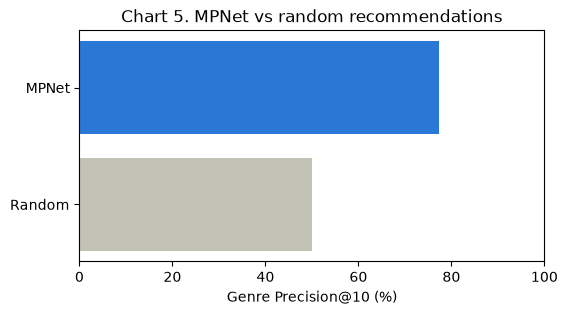

<Figure size 640x480 with 0 Axes>

In [12]:
plt.figure(figsize=(6, 3))
plt.barh(["Random", "MPNet"], [random_p10 * 100, model_p10 * 100], color=["#c3c2b7", "#2a78d6"])
plt.xlabel("Genre Precision@10 (%)")
plt.title("Chart 5. MPNet vs random recommendations")
plt.xlim(0, 100)
plt.show()
plt.savefig("results/figures/chart5_genre_test.png", dpi=150, bbox_inches="tight")

Our results show that 77.3% of MPNet's top-10 recommendations share at least one genre with the original movie, compared with 50.1% for random movies (**+27.1 percentage points**). The model never saw the genres, so this shows that it groups movies by the meaning of their plots.

### Representative examples
Five well-known movies from different genres, to judge the recommendations by eye.

In [13]:
for title in ["The Dark Knight", "Toy Story", "The Notebook", "The Conjuring", "Interstellar"]:
    display(recommend(title, 5))

Because you liked: The Dark Knight (Drama, Action, Crime, Thriller)


,title,genres,vote_average,similarity
0,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",7.6,0.828
1,Batman,"[Fantasy, Action]",7.0,0.810
2,Batman Begins,"[Action, Crime, Drama]",7.5,0.770
3,Batman v Superman: Dawn of Justice,"[Action, Adventure, Fantasy]",5.7,0.696
4,Batman Forever,"[Action, Crime, Fantasy]",5.2,0.686


Because you liked: Toy Story (Animation, Comedy, Family)


,title,genres,vote_average,similarity
0,Toy Story 3,"[Animation, Family, Comedy]",7.6,0.833
1,Toy Story 2,"[Animation, Comedy, Family]",7.3,0.817
2,Elf,"[Comedy, Family, Fantasy]",6.4,0.482
3,Pinocchio,"[Animation, Family]",6.9,0.474
4,Alvin and the Chipmunks: The Squeakquel,"[Comedy, Family, Animation, Fantasy, Music]",5.4,0.449


Because you liked: The Notebook (Romance, Drama)


,title,genres,vote_average,similarity
0,Angel Eyes,"[Drama, Romance, Thriller]",5.6,0.698
1,The Incredibly True Adventure of Two Girls In ...,"[Comedy, Drama, Romance]",5.7,0.687
2,Closer,"[Drama, Romance]",6.7,0.685
3,Gone with the Wind,"[Drama, Romance, War]",7.7,0.675
4,Before Sunrise,"[Drama, Romance]",7.7,0.663


Because you liked: The Conjuring (Horror, Thriller)


,title,genres,vote_average,similarity
0,The Apparition,"[Horror, Thriller]",4.5,0.742
1,The Conjuring 2,[Horror],7.0,0.726
2,The Amityville Horror,"[Horror, Thriller, Drama]",6.0,0.696
3,Insidious: Chapter 2,"[Horror, Thriller]",6.5,0.695
4,Beetlejuice,"[Fantasy, Comedy]",7.1,0.691


Because you liked: Interstellar (Adventure, Drama, Science Fiction)


,title,genres,vote_average,similarity
0,Star Trek Beyond,"[Action, Adventure, Science Fiction]",6.6,0.561
1,The Black Hole,"[Adventure, Family, Science Fiction, Action]",6.1,0.522
2,Prometheus,"[Science Fiction, Adventure, Mystery]",6.3,0.498
3,Stargate: The Ark of Truth,"[Adventure, Science Fiction]",6.9,0.494
4,Tomorrowland,"[Adventure, Family, Mystery, Science Fiction]",6.2,0.473


**Analysis of the 5 examples (plot only, MPNet).**
- **The Dark Knight → 5/5 relevant**: all Batman films (*The Dark Knight Rises*, *Batman Begins*, *Batman* 1989, ...). The overviews share names like Batman and Gotham, so sequels are found very easily (similarity ≈ 0.8). But there is no diversity, and the model ignores quality: *Batman Forever* (rating 5.2) is recommended next to much better films.
- **Toy Story → 4/5.** *Toy Story 3* and *2* come first (similarity 0.83 and 0.82), and after them similarity drops to ≈ 0.48. *Pinocchio* is a clever thematic match (a toy that comes alive), while *Elf* only shares the family-comedy tone.
- **The Notebook → 4/5.** All five are romances (*Before Sunrise*, *Gone with the Wind*, ...). *Closer* is a cynical drama about cheating: it matches the topic "love" but not the warm tone of The Notebook.
- **The Conjuring → 4/5.** Haunted-house horror (*The Conjuring 2*, *The Amityville Horror*, *Insidious: Chapter 2*). The strange one is *Beetlejuice*: its plot is also about ghosts haunting a family's house, but it is a comedy. The model matches **what happens** in the story, not the genre or tone.
- **Interstellar → 4/5.** All five are space adventures (*Prometheus*, *Star Trek Beyond*, ...), but similarity is lower (≈ 0.47–0.56), and none captures the emotional father–daughter story. *Tomorrowland* is the weakest match.



## Limitation of the genre check
Two movies can be very similar in terms of feel, main cast, producer etc., but have different genres. Our model would potentially mark such a recommendation incorrect, even though the chances of someone liking it are actually high. So we propose 2 improvements:
1. **An improved "hybrid" recommender** that also uses actors, director and keywords, not only the plot.
2. **A test with real people:** the [MovieLens](https://grouplens.org/datasets/movielens/32m/) dataset (32 million ratings from about 200 000 users).
   If a user liked movie A, how many of the 10 recommendations for A did **the same user** also like? This works for any reason of similarity
   (plot, actor, director, mood) and does not use genres at all.

## 6B. Hybrid recommender + test with MovieLens dataset

**Hybrid score** for two movies:

`score = α · plot similarity (MPNet)  +  (1 − α) · metadata similarity`

- **Metadata similarity** is the average of three overlaps: shared **actors**, same **director**, shared **keywords**.
 	We do not use model to predict that.
- **α** is a coefficient to find the best mix of plot similarity and metadata similarity. α = 1.0 means "plot only" (our original model), and α = 0 means only metadata information.

In [14]:
from sklearn.preprocessing import MultiLabelBinarizer

META = [MultiLabelBinarizer(sparse_output=True).fit_transform(df[col]).tocsr() for col in ["cast_top", "director", "keywords"]]

SIZES = [np.asarray(M.sum(axis=1)).ravel() for M in META]

def meta_similarity(i, rows):
    total = np.zeros(len(rows))
    for M, size in zip(META, SIZES):
        shared = (M @ M[i].T).toarray().ravel()[rows].astype(float)
        union = size[rows] + size[i] - shared
        total += np.divide(shared, union, out=np.zeros(len(rows)), where=union > 0)
    return total / 3

def hybrid_scores(i, rows, alpha):
    return alpha * (embeddings[rows] @ embeddings[i]) + (1 - alpha) * meta_similarity(i, rows)

def recommend_hybrid(title, k=5, alpha=0.2):
    i = find_movie(title)
    if i is None:
        return None
    scores = hybrid_scores(i, np.arange(len(df)), alpha)
    scores[i] = -np.inf
    top = np.argsort(-scores)[:k]
    result = df.loc[top, ["title", "genres"]].copy()
    result["director"] = df.loc[top, "director"].str.join(", ")
    result["main actors"] = df.loc[top, "cast_top"].str[:3].str.join(", ")
    result["score"] = scores[top].round(3)
    return result.reset_index(drop=True)

**What the above cell does.**
1. **Metadata tables:** for actors (top 5), directors and keywords, it creates a 0/1 table with one row per movie and one column per name (1 = the movie has this actor/director/keyword).
2. **Metadata similarity:** it creates average score for the similarities in the metadata.
3. **Hybrid score:**
`α × plot similarity (MPNet) + (1 − α) × metadata similarity`.
α = 1 means plot only; a smaller α gives more weight to actors, director and keywords.
4. **Recommend:** it ranks the recommended movies, and shows why this movie was recommended.

Since the director overlapping is the significant metadata similarity score, the recommendation system often retrieves movies with the same director.

In [15]:
import os, ssl, shutil, certifi, urllib.request, zipfile
if not os.path.exists("movielens.zip"):
    context = ssl.create_default_context(cafile=certifi.where())
    with urllib.request.urlopen("https://files.grouplens.org/datasets/movielens/ml-32m.zip", context=context) as r, \
         open("movielens.zip.part", "wb") as f:
        shutil.copyfileobj(r, f)
    os.replace("movielens.zip.part", "movielens.zip")
with zipfile.ZipFile("movielens.zip") as z:
    ratings = pd.read_csv(z.open("ml-32m/ratings.csv"), usecols=["userId", "movieId", "rating"],
                          dtype={"userId": "int32", "movieId": "int32", "rating": "float32"})
    links = pd.read_csv(z.open("ml-32m/links.csv"))
ratings = ratings[ratings["rating"] >= 4]
row_of = pd.Series(df.index, index=df["id"])
links = links.dropna(subset=["tmdbId"])
links["row"] = links["tmdbId"].astype(int).map(row_of)
links = links.dropna(subset=["row"]).astype({"row": int})
catalog = np.sort(links["row"].unique())
liked = ratings.merge(links[["movieId", "row"]], on="movieId")[["userId", "row"]]
del ratings
counts = liked.groupby("userId").size()
print(f"Movies in both datasets: {len(catalog)} | users: {len(counts):,}")
print("Successfully dowloaded the dataset")

Movies in both datasets: 4633 | users: 200,557
Successfully dowloaded the dataset


In [16]:
MIN_LIKES = 200
eligible = counts[counts >= MIN_LIKES].index
N_USERS = 2000
rng = np.random.default_rng(42)
sample = rng.choice(eligible, size=min(2 * N_USERS, len(eligible)), replace=False)
user_likes = liked[liked["userId"].isin(sample)].groupby("userId")["row"].apply(set)
print(f"Eligible users (>= {MIN_LIKES} likes): {len(eligible):,} | sampled: {len(user_likes)}")

Eligible users (>= 200 likes): 8,228 | sampled: 4000


**Test procedure:**
1. Split the users randomly into two halves: a **validation** half and a **test** half.
2. On the **validation** users, we try α = 1.0, 0.9, ..., 0.1 and pick the best one.
3. Report the final numbers only on the **test** users, who were never used to choose α.

For each user(user with 200 likes or more), we pick up to 5 movies they liked (rated 4 stars or more) and use each one as a **query**.

For each query, the method recommends 10 movies, and we check how many of them appear **anywhere in that user's full list of liked movies**.

The share of hits out of 10 is **MovieLens Precision@10** (e.g. 1 hit = 10%), averaged over all queries and users.
A **random** recommender (10 random movies) is the baseline.

In [17]:
rng = np.random.default_rng(42)
users = rng.permutation(user_likes.index)
val_users, test_users = users[: len(users) // 2], users[len(users) // 2 :]
ALPHAS = [1.0, 0.9, 0.8, 0.7, 0.6, 0.5, 0.4, 0.3, 0.2, 0.1]

def evaluate(user_ids, alphas):
    results = {a: [] for a in alphas}
    results["Random"] = []
    for u in user_ids:
        likes = user_likes[u]
        for seed in rng.choice(sorted(likes), min(5, len(likes)), replace=False):
            others = likes - {seed}
            plot = embeddings[catalog] @ embeddings[seed]
            meta = meta_similarity(seed, catalog)
            for a in alphas:
                scores = a * plot + (1 - a) * meta
                scores[catalog == seed] = -np.inf
                top10 = catalog[np.argpartition(-scores, 10)[:10]]
                results[a].append(len(others & set(top10)) / 10)
            random10 = rng.choice(catalog[catalog != seed], 10, replace=False)
            results["Random"].append(len(others & set(random10)) / 10)
    return {key: np.mean(v) for key, v in results.items()}

val = evaluate(val_users, ALPHAS)
print("Validation users:", {k: f"{v:.2%}" for k, v in val.items()})
BEST_ALPHA = max(ALPHAS, key=lambda a: val[a])
print("Best alpha on validation users:", BEST_ALPHA)

test = evaluate(test_users, [1.0, BEST_ALPHA])
print(f"\nTEST users, MovieLens Precision@10")
print(f"  Random:                       {test['Random']:.2%}")
print(f"  Plot only (MPNet):            {test[1.0]:.2%}")
print(f"  Hybrid (alpha = {BEST_ALPHA}):         {test[BEST_ALPHA]:.2%}")
print(f"  Hybrid vs plot only: {(test[BEST_ALPHA] - test[1.0]) * 100:+.2f} percentage points")

Validation users: {1.0: '11.66%', 0.9: '11.93%', 0.8: '12.41%', 0.7: '13.34%', 0.6: '14.93%', 0.5: '16.89%', 0.4: '17.72%', 0.3: '18.17%', 0.2: '18.52%', 0.1: '18.52%', 'Random': '6.32%'}
Best alpha on validation users: 0.2

TEST users, MovieLens Precision@10
  Random:                       6.56%
  Plot only (MPNet):            11.32%
  Hybrid (alpha = 0.2):         18.24%
  Hybrid vs plot only: +6.92 percentage points


This shows us that alpha at 0.2 is the best coeficcient.

Users tend to like and watch movies with the similar cast and director and like them more.

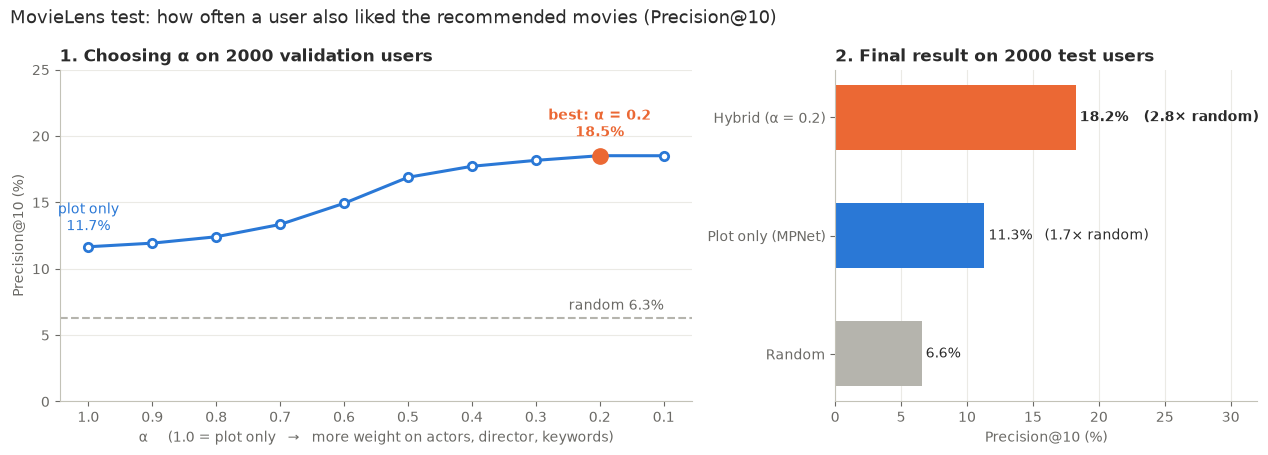

In [18]:
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#b5b4ad", "#2b2b2b", "#6b6a66"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

alphas = sorted(ALPHAS, reverse=True)
scores = [val[a] * 100 for a in alphas]
ax1.plot(range(len(alphas)), scores, color=BLUE, linewidth=2.2, marker="o", markersize=6, markerfacecolor="white", markeredgewidth=2)
best = alphas.index(BEST_ALPHA)
ax1.plot(best, val[BEST_ALPHA] * 100, "o", color=ORANGE, markersize=11, zorder=3)
ax1.annotate(f"best: α = {BEST_ALPHA}\n{val[BEST_ALPHA] * 100:.1f}%", (best, val[BEST_ALPHA] * 100), xytext=(0, 14),
             textcoords="offset points", ha="center", color=ORANGE, fontweight="bold")
ax1.annotate(f"plot only\n{val[1.0] * 100:.1f}%", (0, val[1.0] * 100), xytext=(0, 12), textcoords="offset points", ha="center", color=BLUE)
ax1.axhline(val["Random"] * 100, color=GREY, linestyle="--", linewidth=1.5)
ax1.text(len(alphas) - 1, val["Random"] * 100 + 0.6, f"random {val['Random'] * 100:.1f}%", ha="right", color=MUTED)
ax1.set_xticks(range(len(alphas)))
ax1.set_xticklabels([str(a) for a in alphas])
ax1.set_xlabel("α     (1.0 = plot only   →   more weight on actors, director, keywords)", color=MUTED)
ax1.set_ylabel("Precision@10 (%)", color=MUTED)
ax1.set_ylim(0, 25)
ax1.set_title("1. Choosing α on 2000 validation users", loc="left", fontweight="bold", color=INK)

names = ["Random", "Plot only (MPNet)", f"Hybrid (α = {BEST_ALPHA})"]
values = [test["Random"] * 100, test[1.0] * 100, test[BEST_ALPHA] * 100]
ax2.barh(names, values, color=[GREY, BLUE, ORANGE], height=0.55)
for y, v in enumerate(values):
    extra = "" if y == 0 else f"   ({v / values[0]:.1f}× random)"
    ax2.text(v + 0.3, y, f"{v:.1f}%{extra}", va="center", color=INK, fontweight="bold" if y == 2 else "normal")
ax2.set_xlim(0, 32)
ax2.set_xlabel("Precision@10 (%)", color=MUTED)
ax2.set_title("2. Final result on 2000 test users", loc="left", fontweight="bold", color=INK)

for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED)
    ax.grid(axis="x" if ax is ax2 else "y", color="#ebeae5", linewidth=0.8)
    ax.set_axisbelow(True)

fig.suptitle("MovieLens test: how often a user also liked the recommended movies (Precision@10)", x=0.01, ha="left", fontsize=13, color=INK)
plt.tight_layout()
plt.savefig("results/figures/chart6_movielens.png", dpi=150, bbox_inches="tight")
plt.show()

### Example: plot only vs hybrid
Does adding actors and director change the recommendations? *Interstellar* is a good test.

In [19]:
i = find_movie("Interstellar")
#Find the row number of the movie (works with partial titles too, e.g. "interstellar" or "dark knight").
print(df.loc[i, "title"])
print(df.loc[i, "overview"])
#Print the full plot description. print() shows the whole text, while a table would cut long text with "...".

Interstellar
Interstellar chronicles the adventures of a group of explorers who make use of a newly discovered wormhole to surpass the limitations on human space travel and conquer the vast distances involved in an interstellar voyage.


In [20]:
display(recommend("interstellar", 5))
#Plot only: movies with similar STORIES.
display(recommend_hybrid("Interstellar", 5, alpha=BEST_ALPHA))
#Hybrid: also rewards shared actors, the same director and shared keywords.

Because you liked: Interstellar (Adventure, Drama, Science Fiction)


,title,genres,vote_average,similarity
0,Star Trek Beyond,"[Action, Adventure, Science Fiction]",6.6,0.561
1,The Black Hole,"[Adventure, Family, Science Fiction, Action]",6.1,0.522
2,Prometheus,"[Science Fiction, Adventure, Mystery]",6.3,0.498
3,Stargate: The Ark of Truth,"[Adventure, Science Fiction]",6.9,0.494
4,Tomorrowland,"[Adventure, Family, Mystery, Science Fiction]",6.2,0.473


,title,genres,director,main actors,score
0,The Dark Knight Rises,"[Action, Crime, Drama, Thriller]",Christopher Nolan,"Christian Bale, Michael Caine, Gary Oldman",0.360
1,The Prestige,"[Drama, Mystery, Thriller]",Christopher Nolan,"Hugh Jackman, Christian Bale, Michael Caine",0.357
2,The Dark Knight,"[Drama, Action, Crime, Thriller]",Christopher Nolan,"Christian Bale, Heath Ledger, Aaron Eckhart",0.335
3,Memento,"[Mystery, Thriller]",Christopher Nolan,"Guy Pearce, Carrie-Anne Moss, Joe Pantoliano",0.322
4,Batman Begins,"[Action, Crime, Drama]",Christopher Nolan,"Christian Bale, Michael Caine, Liam Neeson",0.321


In [21]:
movie_title_hybrid = "Fight Club"  #@param {type:"string"}
how_many_hybrid = 11  #@param {type:"slider", min:1, max:20, step:1}
recommend_hybrid(movie_title_hybrid, how_many_hybrid, alpha=BEST_ALPHA)

,title,genres,director,main actors,score
0,Se7en,"[Crime, Mystery, Thriller]",David Fincher,"Brad Pitt, Morgan Freeman, Gwyneth Paltrow",0.418
1,The Curious Case of Benjamin Button,"[Fantasy, Drama, Thriller, Mystery, Romance]",David Fincher,"Cate Blanchett, Brad Pitt, Tilda Swinton",0.399
2,Panic Room,"[Crime, Drama, Thriller]",David Fincher,"Jodie Foster, Kristen Stewart, Forest Whitaker",0.376
3,Zodiac,"[Crime, Drama, Mystery, Thriller]",David Fincher,"Jake Gyllenhaal, Robert Downey Jr., Mark Ruffalo",0.356
4,The Girl with the Dragon Tattoo,"[Thriller, Crime, Mystery, Drama]",David Fincher,"Daniel Craig, Rooney Mara, Christopher Plummer",0.349
5,The Game,"[Drama, Thriller, Mystery]",David Fincher,"Michael Douglas, Sean Penn, Deborah Kara Unger",0.349
6,Gone Girl,"[Mystery, Thriller, Drama]",David Fincher,"Ben Affleck, Rosamund Pike, Carrie Coon",0.316
7,The Social Network,[Drama],David Fincher,"Jesse Eisenberg, Andrew Garfield, Justin Timbe...",0.304
8,Alien³,"[Science Fiction, Action, Horror]",David Fincher,"Sigourney Weaver, Charles S. Dutton, Charles D...",0.304
9,American Psycho,"[Thriller, Drama, Crime]",Mary Harron,"Christian Bale, Willem Dafoe, Jared Leto",0.144


**Results**

(MovieLens 32M, 2000 active users with ≥ 200 liked movies, not used for tuning): random 6.51%, plot only (MPNet) **11.33%** (1.7× random), hybrid with α = 0.2 **18.24%** (2.8× random, +6.92 pp / +61% over plot only). Validation (18.52%) and test (18.24%) are close, so the chosen α generalizes.

 α = 0.1–0.3 give almost the same result.

**Drawback:** with a low α, the hybrid mostly recommends films by the same director: five Fincher films for *Fight Club* (including *Benjamin Button*, a romantic fantasy, only because of Fincher and Pitt), and five Nolan films and no space movie for *Interstellar*.

Real users like this more, so the score goes up, but the lists become only about 1 director and actor.

### Popularity check
The MovieLens test can favour popular movies: they are rated by many more users, so recommending them is "rewarded" more often.
Here we measure how popular the recommended movies are (number of TMDB votes) for each method. If the hybrid recommends
much more popular movies than plot only, part of its MovieLens gain may come from popularity rather than better similarity.

In [22]:
pop = df["vote_count"].to_numpy()
rating = df["vote_average"].to_numpy()
popular_line = np.quantile(pop[catalog], 0.9)
methods = {"Plot only (MPNet)": 1.0, f"Hybrid (alpha = {BEST_ALPHA})": BEST_ALPHA}
rec_votes = {name: [] for name in methods}
rec_rating = {name: [] for name in methods}

for seed in catalog:
    plot = embeddings[catalog] @ embeddings[seed]
    meta = meta_similarity(seed, catalog)
    for name, a in methods.items():
        scores = a * plot + (1 - a) * meta
        scores[catalog == seed] = -np.inf
        top10 = catalog[np.argpartition(-scores, 10)[:10]]
        rec_votes[name].extend(pop[top10])
        rec_rating[name].extend(rating[top10])

popularity = pd.DataFrame({
    "median votes": [np.median(pop[catalog])] + [np.median(v) for v in rec_votes.values()],
    "% from the top-10% most popular": [10.0] + [np.mean(np.array(v) >= popular_line) * 100 for v in rec_votes.values()],
    "median TMDB rating": [np.median(rating[catalog])] + [np.median(v) for v in rec_rating.values()],
}, index=["Whole catalog (reference)"] + list(methods))

popularity.round(1)

,median votes,% from the top-10% most popular,median TMDB rating
Whole catalog (reference),254.0,10.0,6.2
Plot only (MPNet),256.0,9.5,6.3
Hybrid (alpha = 0.2),313.0,11.7,6.3



**Results**

Plot-only recommendations are exactly as popular as the average in general (median 256 vs 254 votes; 9.5% from the top-10% most popular movies vs 10% expected), so the plot model has **no popularity bias**.

The hybrid recommends somewhat more popular movies (median 313 votes, about +23%; 11.7% from the top 10%), because films by famous directors and actors tend to be popular.

The difference is not huge, so the popularity can explain only small portion of the hybrid's "success".

### Did users actually dislike our recommendations?
The main test counts a recommendation as a miss whenever the user did not like it, including when the user simply never watched it.

Here we look **only at recommended movies that the test user actually rated** (any rating from 0.5 to 5 stars) and check how high those ratings were.

If our recommendations were bad, users who watched them would often give them low ratings (≤ 2.5 stars).

In [23]:
with zipfile.ZipFile("movielens.zip") as z:
    all_ratings = pd.read_csv(z.open("ml-32m/ratings.csv"), usecols=["userId", "movieId", "rating"],
                              dtype={"userId": "int32", "movieId": "int32", "rating": "float32"})
all_ratings = all_ratings[all_ratings["userId"].isin(test_users)].merge(links[["movieId", "row"]], on="movieId")
user_ratings = {u: dict(zip(g["row"], g["rating"])) for u, g in all_ratings.groupby("userId")}
del all_ratings

rng = np.random.default_rng(42)
methods = {"Random": None, "Plot only (MPNet)": 1.0, f"Hybrid (alpha = {BEST_ALPHA})": BEST_ALPHA}
given = {name: [] for name in methods}
shown = {name: 0 for name in methods}

for u in test_users:
    rated = user_ratings.get(u, {})
    likes = user_likes[u]
    for seed in rng.choice(sorted(likes), min(5, len(likes)), replace=False):
        plot = embeddings[catalog] @ embeddings[seed]
        meta = meta_similarity(seed, catalog)
        for name, a in methods.items():
            if a is None:
                top10 = rng.choice(catalog[catalog != seed], 10, replace=False)
            else:
                scores = a * plot + (1 - a) * meta
                scores[catalog == seed] = -np.inf
                top10 = catalog[np.argpartition(-scores, 10)[:10]]
            shown[name] += 10
            given[name].extend(rated[m] for m in top10 if m in rated)

rated_check = pd.DataFrame({
    "% of recs the user has rated": [len(given[n]) / shown[n] * 100 for n in methods],
    "average rating (0.5–5)": [np.mean(given[n]) for n in methods],
    "% liked (≥ 4 stars)": [np.mean(np.array(given[n]) >= 4) * 100 for n in methods],
    "% disliked (≤ 2.5 stars)": [np.mean(np.array(given[n]) <= 2.5) * 100 for n in methods],
}, index=list(methods))
rated_check.round(1)

,% of recs the user has rated,average rating (0.5–5),% liked (≥ 4 stars),% disliked (≤ 2.5 stars)
Random,12.6,3.6,50.6,16.7
Plot only (MPNet),19.4,3.8,59.1,11.8
Hybrid (alpha = 0.2),29.0,3.9,62.9,9.6


**Results**

This check shows that our recommendations have higher rating than a random selection. (58.9% vs 51.5% and 62.8% vs 51.5%)

Also the hybrid is more successul in this check, the reason might be in specific directors and actors that user like, that have an effect on the movie rating overall.


Note that Random selection from all the movies watched retrieves us 51.5% liked films. This is because users will watch films that they think that will like.

In [24]:
import shutil
rows = [
    ("Genre Precision@10 (all movies)", "Random", random_p10),
    ("Genre Precision@10 (all movies)", "Plot only (MPNet)", model_p10),
    ("MovieLens Precision@10 (test users)", "Random", test["Random"]),
    ("MovieLens Precision@10 (test users)", "Plot only (MPNet)", test[1.0]),
    ("MovieLens Precision@10 (test users)", f"Hybrid (alpha = {BEST_ALPHA})", test[BEST_ALPHA]),
]
pd.DataFrame(rows, columns=["test", "method", "precision_at_10"]).to_csv("results/evaluation.csv", index=False)
pd.Series(val, name="validation_precision_at_10").to_csv("results/alpha_validation.csv", index_label="alpha")
popularity.round(1).to_csv("results/popularity_check.csv")
rated_check.round(1).to_csv("results/rated_check.csv")
examples = []
for title in ["The Dark Knight", "Toy Story", "The Notebook", "The Conjuring", "Interstellar", "Fight Club"]:
    plot = recommend(title, 5)
    if plot is None:
        continue
    plot.insert(0, "method", "Plot only (MPNet)")
    hybrid = recommend_hybrid(title, 5, alpha=BEST_ALPHA)
    hybrid.insert(0, "method", f"Hybrid (alpha = {BEST_ALPHA})")
    for table in (plot, hybrid):
        table.insert(0, "query", title)
        examples.append(table)
pd.concat(examples).to_csv("results/example_recommendations.csv", index=False)

shutil.make_archive("results", "zip", "results")
try:
    from google.colab import files
    files.download("results.zip")
except ImportError:
    print("Not running in Colab: results.zip is in the working folder.")
print(sorted(os.listdir("results")), sorted(os.listdir("results/figures")))

Because you liked: The Dark Knight (Drama, Action, Crime, Thriller)
Because you liked: Toy Story (Animation, Comedy, Family)
Because you liked: The Notebook (Romance, Drama)
Because you liked: The Conjuring (Horror, Thriller)
Because you liked: Interstellar (Adventure, Drama, Science Fiction)
Because you liked: Fight Club (Drama)
Not running in Colab: results.zip is in the working folder.
['alpha_validation.csv', 'evaluation.csv', 'example_recommendations.csv', 'figures', 'popularity_check.csv', 'rated_check.csv'] ['chart5_genre_test.png', 'chart6_movielens.png', 'eda_charts.png']


## 7. Results and conclusion

### Results at a glance
| Test | Random | Plot only (MPNet) | Hybrid (α = 0.2) |
|---|---|---|---|
| Genre Precision@10 (all movies) | 50.1% | **77.3%** | – |
| MovieLens Precision@10 (2000 test users) | 6.5% | 11.3% | **18.2%** |
| Watched recommendations rated ≤ 2.5★ | 16.3% | 11.8% | **9.6%** |

**Does it support the goal?**

Yes. Without seeing genres, the model matches them far more often than random (Chart 5), real users like its recommendations 1.7× more than random ones, and 2.8× more with actors and director added (Chart 6).

**Strengths**
- Works from text only: new movies can be recommended right away.
- Understands meaning, so free-text search works with your own words.
- Fast: movies are encoded once, and each search takes milliseconds.

**Weaknesses**
- Overviews are short: different films can sound alike, and similar films can be described differently.
- With a low α, the hybrid mostly recommends films by the same director (all Nolan for *Interstellar*).
- Some of the movies our model recommends even if it is suitable and similar are not popular, so not many people have watched it and left a review.

**Improvements**
- Diversity rule: at most 2 films per director in the top 5.
- Mix in the movie's rating, so good and similar films come first.
- Tune separate weights for actors, director and keywords.


Overall, the recommendations make sense and can help discover niche films with similar plots. Longer plot descriptions would probably improve the results, but would need a model that can read longer texts.

## 8. Reproducibility
- **Run:** open in Google Colab → Runtime → Change runtime type → T4 GPU → Runtime → Run all.
- **Libraries:** `sentence-transformers`, `datasets` (installed in Section 1); `numpy`, `pandas`, `matplotlib`, `scikit-learn` (already in Colab).
- **Dataset:** `load_dataset("AiresPucrs/tmdb-5000-movies")`: public, no login. Original source: TMDB via Kaggle.
- **Model:** `sentence-transformers/all-mpnet-base-v2`, downloaded automatically from https://huggingface.co/sentence-transformers/all-mpnet-base-v2
- **Evaluation data:** MovieLens 32M (stable benchmark by GroupLens), downloaded automatically from https://files.grouplens.org/datasets/movielens/ml-32m.zip (≈ 240 MB). Only users with ≥ 200 liked movies are used, and a random sample of 2000 + 2000 of them. The data is not redistributed in this repository.
- **Randomness:** the random baseline, the user sample and the split use a fixed seed (42), so the results repeat exactly.
- **Outputs:** charts in `results/figures/`, numbers in `results/evaluation.csv`, `results/alpha_validation.csv`, example outputs in `results/example_recommendations.csv`.
- **Difficulties / limitations:**
  - No ready "similar movies" labels, so genres and real-user ratings are used as indirect checks.
  - MovieLens 32M has 32 million ratings, so it is loaded with small number types and only a sample of users is evaluated, to fit into free Colab memory and time.
  - Results can differ by about ±0.1 percentage points between environments (CPU vs GPU, different library versions), because the random sample of users and floating-point results change slightly. The conclusions stay the same.
- **AI assistance:** Claude helped structure and explain the code, human checked and fixed mistakes. All experiments were run, interpreted by us.